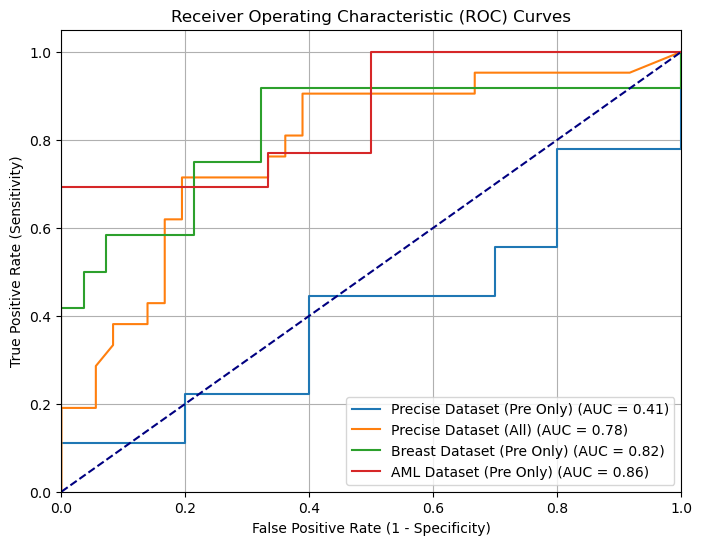

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import pandas as pd
plt.figure(figsize=(8, 6))



score_df_prec_pre = pd.read_csv("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/precise_dataset_result/pre_treatment/loo_results.csv", sep=',')
y_true_prec_pre = score_df_prec_pre['Label']
y_score_prec_pre = score_df_prec_pre['Score']
fpr_prec_pre, tpr_prec_pre, _ = roc_curve(y_true_prec_pre, y_score_prec_pre)
roc_auc_prec_pre = auc(fpr_prec_pre, tpr_prec_pre)
plt.plot(fpr_prec_pre, tpr_prec_pre, label=f'Precise Dataset (Pre Only) (AUC = {roc_auc_prec_pre:.2f})')

score_df_prec = pd.read_csv("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/precise_dataset_result/loo_results.csv", sep=',')
y_true_prec = score_df_prec['Label']
y_score_prec = score_df_prec['Score']
fpr_prec, tpr_prec, _ = roc_curve(y_true_prec, y_score_prec)
roc_auc_prec = auc(fpr_prec, tpr_prec)
plt.plot(fpr_prec, tpr_prec, label=f'Precise Dataset (All) (AUC = {roc_auc_prec:.2f})')

score_df_bio = pd.read_csv("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/biokey_small_paper_run/loo_results.csv", sep=',')
y_true_bio = score_df_bio['Label']
y_score_bio = score_df_bio['Score']
fpr_bio, tpr_bio, _ = roc_curve(y_true_bio, y_score_bio)
roc_auc_bio = auc(fpr_bio, tpr_bio)
plt.plot(fpr_bio, tpr_bio, label=f'Breast Dataset (Pre Only) (AUC = {roc_auc_bio:.2f})')

score_df_aml = pd.read_csv("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/GSE235923_ped_AML_6rel_14resp/loo_results.csv", sep=',')
y_true_aml = score_df_aml['Label']
y_score_aml = score_df_aml['Score']
fpr_aml, tpr_aml, _ = roc_curve(y_true_aml, y_score_aml)
roc_auc_aml = auc(fpr_aml, tpr_aml)
plt.plot(fpr_aml, tpr_aml, label=f'AML Dataset (Pre Only) (AUC = {roc_auc_aml:.2f})')

# Plot the diagonal baseline (random guessing)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')

# Customizing the graph aesthetics
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [14]:
import scanpy as sc
adata_aml = sc.read_h5ad("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/GSE235923_ped_AML_6rel_14resp/AML_int.h5ad")
adata_prec = sc.read_h5ad("precise_dataset.h5ad")
adata_prec_pre = sc.read_h5ad("precise_dataset_pre.h5ad")
adata_bio =  sc.read_h5ad("biokey_small.h5ad")

C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\site-packages\anndata\_core\anndata.py:1811: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [34]:
adata_prec_pre = sc.read_h5ad("precise_dataset_pre.h5ad")

In [49]:
adatas = {
    "Dataset_AML": adata_aml,
    "Dataset_Precise": adata_prec,
    "Dataset_Precise_Pre": adata_prec_pre,
    "Dataset_Breast": adata_bio
}

# Column in each adata.obs holding the patient/sample ID (can differ per dataset)
patient_col = {
    "Dataset_AML": "orig.ident",
    "Dataset_Precise": "sample",
    "Dataset_Precise_Pre": "sample",
    "Dataset_Breast": "donor_id",
}

# AUC from the pipeline for each dataset (same keys as adatas)
aucs = {
    "Dataset_AML": roc_auc_aml,
    "Dataset_Precise": roc_auc_prec,
    "Dataset_Precise_Pre": roc_auc_prec_pre,
    "Dataset_Breast": roc_auc_bio
}

In [50]:
rows = []
per_patient_counts = {}

for name, adata in adatas.items():
    counts = adata.obs[patient_col[name]].value_counts()
    counts = counts[counts > 0]  # drop unused categorical levels
    per_patient_counts[name] = counts

    rows.append({
        "dataset": name,
        "n_patients": counts.shape[0],
        "n_cells_total": counts.sum(),
        "median_cells_per_patient": counts.median(),
        "mean_cells_per_patient": counts.mean(),
        "min_cells_per_patient": counts.min(),
        "auc": aucs[name],
    })

summary = pd.DataFrame(rows).set_index("dataset")
summary.to_csv("dataset_summary.csv")
summary.round(2)

,n_patients,n_cells_total,median_cells_per_patient,mean_cells_per_patient,min_cells_per_patient,auc
dataset,,,,,,
Dataset_AML,19,57520,3417.0,3027.37,910,0.86
Dataset_Precise,57,16291,313.0,285.81,43,0.78
Dataset_Precise_Pre,19,5928,330.0,312.00,163,0.41
Dataset_Breast,40,30395,708.0,759.88,56,0.82


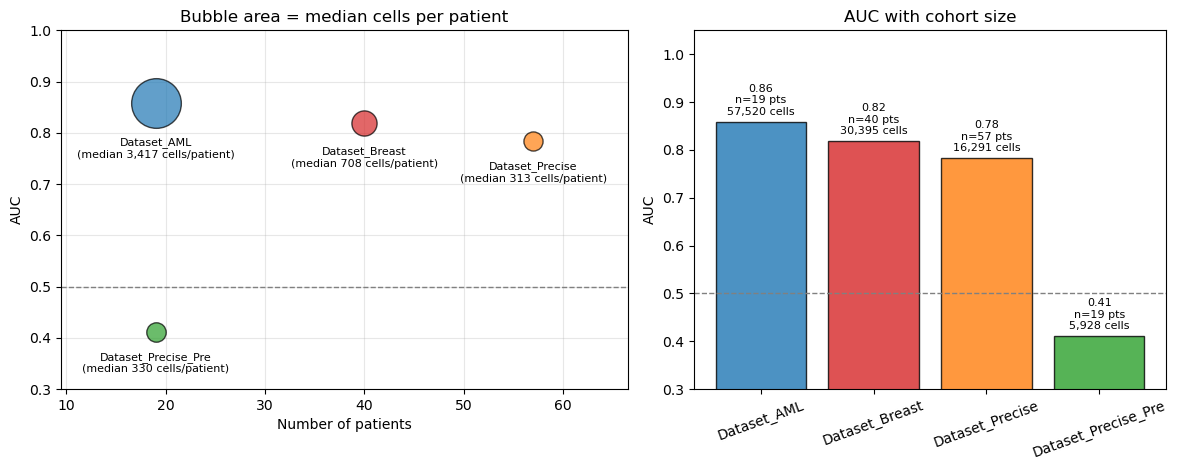

In [51]:
import matplotlib.pyplot as plt
colors = plt.cm.tab10(np.arange(len(summary)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})

# --- Left: bubble plot ---
ax = axes[0]
sizes = 80 + 1200 * summary["median_cells_per_patient"] / summary["median_cells_per_patient"].max()
for (name, row), c, s in zip(summary.iterrows(), colors, sizes):
    ax.scatter(row["n_patients"], row["auc"], s=s, color=c, alpha=0.7,
               edgecolor="k", zorder=3)
    ax.annotate(f"{name}\n(median {row['median_cells_per_patient']:,.0f} cells/patient)",
                (row["n_patients"], row["auc"]), xytext=(0, -np.sqrt(s) / 2 - 22),
                textcoords="offset points", ha="center", fontsize=8)
ax.axhline(0.5, color="grey", ls="--", lw=1)
ax.set_xlabel("Number of patients")
ax.set_ylabel("AUC")
ax.set_ylim(0.3, 1.0)
ax.margins(x=0.25)
ax.grid(alpha=0.3)
ax.set_title("Bubble area = median cells per patient")

# --- Right: AUC bars annotated with cohort size ---
ax = axes[1]
ordered = summary.sort_values("auc", ascending=False)
bars = ax.bar(ordered.index, ordered["auc"], color=[colors[list(summary.index).index(n)] for n in ordered.index],
              edgecolor="k", alpha=0.8)
for bar, (name, row) in zip(bars, ordered.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, row["auc"] + 0.01,
            f"{row['auc']:.2f}\nn={int(row['n_patients'])} pts\n{int(row['n_cells_total']):,} cells",
            ha="center", va="bottom", fontsize=8)
ax.axhline(0.5, color="grey", ls="--", lw=1)
ax.set_ylim(0.3, 1.05)
ax.set_ylabel("AUC")
ax.set_title("AUC with cohort size")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("size_vs_auc.png", dpi=300)
plt.show()

C:\Users\jhous\AppData\Local\Temp\ipykernel_13360\4171584344.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=[f"{n}\nAUC={aucs[n]:.2f}" for n in order], showfliers=False)


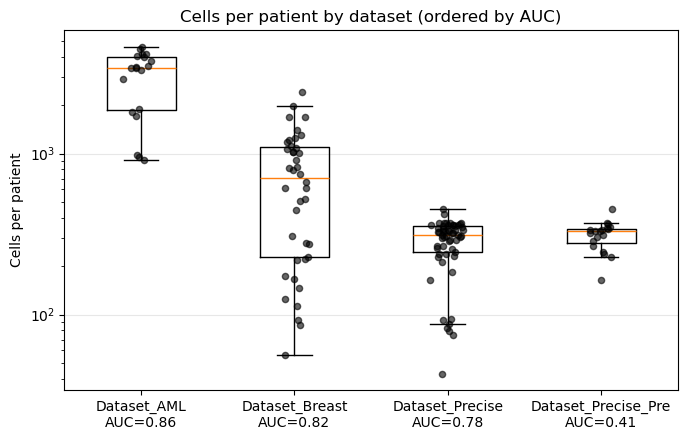

In [52]:
import numpy as np
order = summary.sort_values("auc", ascending=False).index
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(7, 4.5))
data = [per_patient_counts[n].values for n in order]
ax.boxplot(data, labels=[f"{n}\nAUC={aucs[n]:.2f}" for n in order], showfliers=False)
for i, d in enumerate(data, start=1):
    ax.scatter(rng.normal(i, 0.05, size=len(d)), d,
               alpha=0.6, s=20, color="k", zorder=3)
ax.set_yscale("log")
ax.set_ylabel("Cells per patient")
ax.set_title("Cells per patient by dataset (ordered by AUC)")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("cells_per_patient_distribution.png", dpi=300)
plt.show()